## Minimal Code to Evaluate A Neural Compression Model on SDO Image Data

#### 1. Importing required modules

In [1]:
import math

from PIL import Image
import matplotlib.pyplot as plt

import torch
from torchvision import transforms

from google.colab import drive
drive.mount('/content/drive', force_remount=True)
base_location = '/content/drive/My Drive/Academico/CienciasEspaciales/WVU/Research/NeuralNetworks'

#import sys
#sys.path.append(base_location+'/Pytorch/nasa_compressor')

%cd {base_location}/Pytorch/nasa_compressor
!pip install -U pip
!pip install -e .

from tiny_compressai.models import NASACompressor

Mounted at /content/drive
/content/drive/My Drive/Academico/CienciasEspaciales/WVU/Research/NeuralNetworks/Pytorch/nasa_compressor
Obtaining file:///content/drive/My%20Drive/Academico/CienciasEspaciales/WVU/Research/NeuralNetworks/Pytorch/nasa_compressor
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for tiny_compressai (pyproject.toml) ... done
  Created wheel for tiny_compressai: filename=tiny_compressai-1.2.4.dev0-0.editable-cp310-cp310-linux_x86_64.whl size=3325 sha256=3b056d9b910d5311800e5472b7a3457eaf48da4085ef5b3a6e2f3611a50bc436
  Stored in directory: /tmp/pip-ephem-wheel-cache-rp98roir/wheels/4f/ad/98/67b420fde30bc6648bac383fbafaaf6c100c057acba08f3377
Successfully built tiny_compressai
  Attempting uninstall: tiny_compressai
    Found existing installation: tiny_compressai 1.2.4.dev0
    Uninstallin

#### 2. Define saved checkpoint path/image path to be compressed, and the preferred device to use

In [2]:
checkpoint_path = './model_checkpoint/sample_ckpt.ckpt'
image_path = './grayscale_test/AIA20150104_0124_0094.png'
device = 'cuda' if torch.cuda.is_available() else 'cpu'

#### 3. Load model with pretrained weights

In [3]:
state_dict = torch.load(checkpoint_path, map_location=torch.device(device))['state_dict']
net = NASACompressor.from_state_dict(state_dict).eval().to(device)
net.entropy_bottleneck.update()

#### 4. Read the candidate image and plot it for visualization

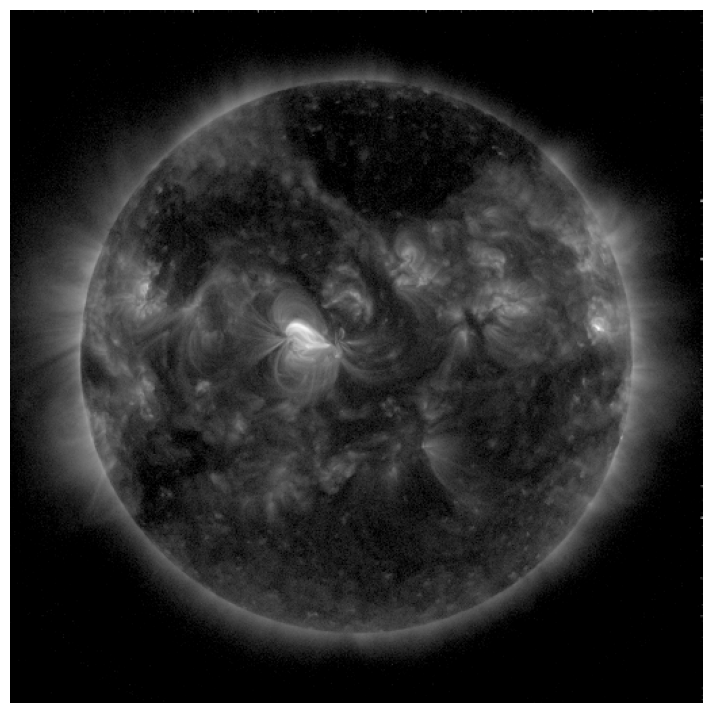

In [4]:
img = Image.open(image_path).convert('L')
x = transforms.ToTensor()(img).unsqueeze(0).to(device)

%matplotlib inline
plt.figure(figsize=(12, 9))
plt.axis('off')
plt.imshow(img, cmap='gray')
plt.show()

#### 5. Feed the network and get the reconstruction + required bit-rate

In [13]:
with torch.no_grad():
    out_net = net.forward(x)
    compressed_val = net.compress(x)
out_net['x_hat'].clamp_(0, 1)
print(out_net.keys())
print(out_net['x_hat'].shape)
print(compressed_val.keys())
print(compressed_val['strings'])
print(compressed_val['shape'])


dict_keys(['x_hat', 'likelihoods'])
torch.Size([1, 1, 512, 512])
torch.Size([32, 32])


In [ ]:
def compute_psnr(a, b):
    mse = torch.mean((a - b)**2).item()
    return -10 * math.log10(mse)

def compute_bpp(out_net):
    size = out_net['x_hat'].size()
    num_pixels = size[0] * size[2] * size[3]
    return sum(torch.log(likelihoods).sum() / (-math.log(2) * num_pixels)
              for likelihoods in out_net['likelihoods'].values()).item()

#### 6. Report PSNR and Bit-rate

In [ ]:
print(f'PSNR: {compute_psnr(x, out_net["x_hat"]):.2f}dB')
print(f'Bit-rate: {compute_bpp(out_net):.3f} bpp')

#### 7. Visualize the reconstruction

In [ ]:
rec_net = transforms.ToPILImage()(out_net['x_hat'].squeeze().cpu())

%matplotlib inline
fix, axes = plt.subplots(1, 2, figsize=(16, 12))
for ax in axes:
    ax.axis('off')

axes[0].imshow(img, cmap='gray')
axes[0].title.set_text('Original')

axes[1].imshow(rec_net, cmap='gray')
axes[1].title.set_text('Reconstructed')


plt.show()